# 01_Yen – PCA

**Thành viên:** Yến 

## Đầu ra
- Notebook/code PCA
- pca_data.csv: dữ liệu sau PCA
- File model PCA và scaler
- Các biểu đồ PCA
- Phần giải thích tại sao chọn số component đó

## 1. Import thư viện

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 2. Đọc dữ liệu

In [3]:
df = pd.read_csv("cleaned_data.csv")
print("Kích thước dữ liệu:", df.shape)
df.head()

Kích thước dữ liệu: (689, 21)


,product_name,price,tv_type,screen_size,resolution,screen_type,operating_system,ram,rom,release_year,...,model_name,rating,num_reviews,specifications,source,monthly_views,monthly_orders,customer_rating,stock_quantity,data_date
0,Smart Tivi QNED LG AI 4K 65 inch 65QNED70BSA,18390000.0,Smart Tivi QNED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,webOS 26,Hãng không công bố,Hãng không công bố,2026.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,7370,453,3.2,145,2026-01-01
1,Google Tivi Sony 4K 65 inch K-65S25VM2,19990000.0,Google Tivi,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2025.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,960,373,4.3,66,2026-01-02
2,Google Tivi QLED TCL AI FHD 40 inch 40S5K,7690000.0,Google Tivi QLED,40 inch,Full HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,1 GB,8 GB,2025.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5490,492,4.5,41,2026-01-03
3,Google Tivi Sony 32 inch KD-32W830K,7690000.0,Google Tivi,32 inch,HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2022.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5291,292,4.7,117,2026-01-04
4,Google Tivi QLED TCL 4K 65 inch 65P7L,18490000.0,Google Tivi QLED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,2 GB,16 GB,2026.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5834,38,3.2,124,2026-01-05


## 3. Kiểm tra các cột

In [4]:
print("Danh sách các cột:")
print(df.columns.tolist())

print("\nKiểu dữ liệu:")
print(df.dtypes)

Danh sách các cột:
['product_name', 'price', 'tv_type', 'screen_size', 'resolution', 'screen_type', 'operating_system', 'ram', 'rom', 'release_year', 'manufacturer', 'model_name', 'rating', 'num_reviews', 'specifications', 'source', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity', 'data_date']

Kiểu dữ liệu:
product_name            str
price               float64
tv_type                 str
screen_size             str
resolution              str
screen_type             str
operating_system        str
ram                     str
rom                     str
release_year        float64
manufacturer            str
model_name              str
rating              float64
num_reviews         float64
specifications          str
source                  str
monthly_views         int64
monthly_orders        int64
customer_rating     float64
stock_quantity        int64
data_date               str
dtype: object


## 4. Chọn các biến đưa vào PCA

In [6]:
pca_features = [
    "price",
    "rating",
    "num_reviews",
    "monthly_views",
    "monthly_orders",
    "customer_rating",
    "stock_quantity"
]
X = df[pca_features].copy()

print("Các biến được sử dụng cho PCA:")
print(pca_features)

print("\nKích thước X:", X.shape)
display(X.head())

Các biến được sử dụng cho PCA:
['price', 'rating', 'num_reviews', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity']

Kích thước X: (689, 7)


,price,rating,num_reviews,monthly_views,monthly_orders,customer_rating,stock_quantity
0,18390000.0,4.3,7.0,7370,453,3.2,145
1,19990000.0,4.3,7.0,960,373,4.3,66
2,7690000.0,4.3,7.0,5490,492,4.5,41
3,7690000.0,4.3,7.0,5291,292,4.7,117
4,18490000.0,4.3,7.0,5834,38,3.2,124


## 5. Kiểm tra missing

In [7]:
print("Số giá trị thiếu trong các biến PCA:")
print(X.isnull().sum())

Số giá trị thiếu trong các biến PCA:
price              0
rating             0
num_reviews        0
monthly_views      0
monthly_orders     0
customer_rating    0
stock_quantity     0
dtype: int64


## 6. Chuẩn hóa dữ liệu

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Kích thước dữ liệu sau Scaling:", X_scaled.shape)

Kích thước dữ liệu sau Scaling: (689, 7)


## 7. Kiểm tra dữ liệu sau Scaling

In [9]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=pca_features
)
display(X_scaled_df.head())

,price,rating,num_reviews,monthly_views,monthly_orders,customer_rating,stock_quantity
0,-0.014676,0.125876,-0.083891,0.805746,1.423346,-1.414605,0.760860
1,-0.002439,0.125876,-0.083891,-1.500560,0.863146,0.495137,-0.612478
2,-0.096511,0.125876,-0.083891,0.129325,1.696443,0.842363,-1.047078
3,-0.096511,0.125876,-0.083891,0.057725,0.295944,1.189588,0.274107
4,-0.013911,0.125876,-0.083891,0.253096,-1.482689,-1.414605,0.395796


## 8. Chạy PCA với toàn bộ components

In [10]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

print("Kích thước sau PCA:")
print(X_pca_full.shape)

Kích thước sau PCA:
(689, 7)


## 9. Explained Variance Ratio

In [11]:
explained_variance = pca_full.explained_variance_ratio_

print("Explained Variance Ratio:")

for i, variance in enumerate(explained_variance, start=1):
    print(f"PC{i}: {variance:.4f} ({variance * 100:.2f}%)")

Explained Variance Ratio:
PC1: 0.1634 (16.34%)
PC2: 0.1516 (15.16%)
PC3: 0.1475 (14.75%)
PC4: 0.1447 (14.47%)
PC5: 0.1359 (13.59%)
PC6: 0.1337 (13.37%)
PC7: 0.1231 (12.31%)


## 10. Cumulative Explained Variance

In [12]:
cumulative_variance = np.cumsum(explained_variance)
print("Cumulative Explained Variance:")

for i, variance in enumerate(cumulative_variance, start=1):
    print(f"PC1 → PC{i}: {variance:.4f} ({variance * 100:.2f}%)")

Cumulative Explained Variance:
PC1 → PC1: 0.1634 (16.34%)
PC1 → PC2: 0.3150 (31.50%)
PC1 → PC3: 0.4625 (46.25%)
PC1 → PC4: 0.6073 (60.73%)
PC1 → PC5: 0.7432 (74.32%)
PC1 → PC6: 0.8769 (87.69%)
PC1 → PC7: 1.0000 (100.00%)


## 11. Vẽ biểu đồ Cumulative Explained Variance

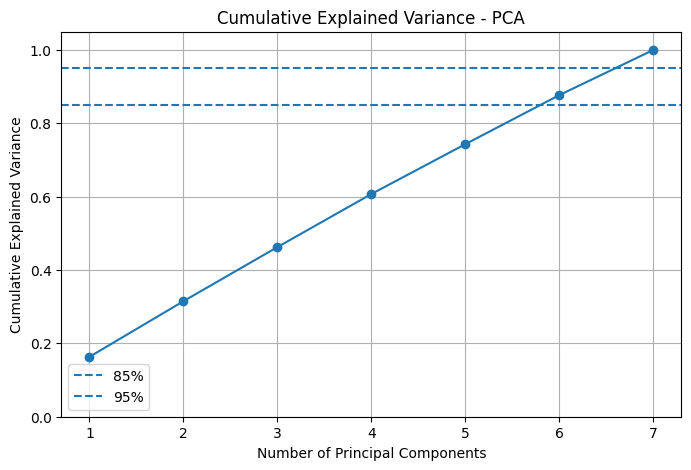

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(y=0.85, linestyle="--", label="85%")
plt.axhline(y=0.95, linestyle="--", label="95%")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance - PCA")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

## 12. Tự động tìm số components

In [14]:
n_components = np.argmax(cumulative_variance >= 0.85) + 1
print("Số components được chọn:", n_components)
print("Cumulative Explained Variance:", f"{cumulative_variance[n_components - 1] * 100:.2f}%")

Số components được chọn: 6
Cumulative Explained Variance: 87.69%


Chọn 6 Principal Components vì 6 components giữ lại 87.69% phương sai của dữ liệu ban đầu, nằm trong khoảng 85–95% theo yêu cầu của đề.

## 13. Chạy PCA chính thức

In [15]:
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)
print("Kích thước dữ liệu sau PCA:", X_pca.shape)

Kích thước dữ liệu sau PCA: (689, 6)


## 14. Tạo pca_data

In [16]:
pca_columns = [
    f"PC{i}"
    for i in range(1, n_components + 1)
]

pca_data = pd.DataFrame(
    X_pca,
    columns=pca_columns
)
display(pca_data.head())

,PC1,PC2,PC3,PC4,PC5,PC6
0,-0.799529,-0.745176,0.250662,0.651425,1.027834,1.584173
1,-0.714665,1.615627,-0.347595,0.434029,-0.324126,-0.246513
2,-0.159861,1.552173,-0.800068,-0.070809,0.372266,0.993834
3,0.379828,0.703338,0.183436,0.071977,0.442691,-0.357089
4,-0.008098,-1.805640,0.345686,0.025658,-0.766348,-0.228735


## 15. Kiểm tra lại dữ liệu PCA

In [17]:
print("Số dòng:", len(pca_data))
print("Số cột:", len(pca_data.columns))

print("\nCác cột PCA:")
print(pca_data.columns.tolist())

Số dòng: 689
Số cột: 6

Các cột PCA:
['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6']


## 16. Lưu file

In [18]:
pca_data.to_csv("pca_data.csv", index=False)
print("Đã lưu file: pca_data.csv")

Đã lưu file: pca_data.csv


## 17. Vẽ PCA 2D

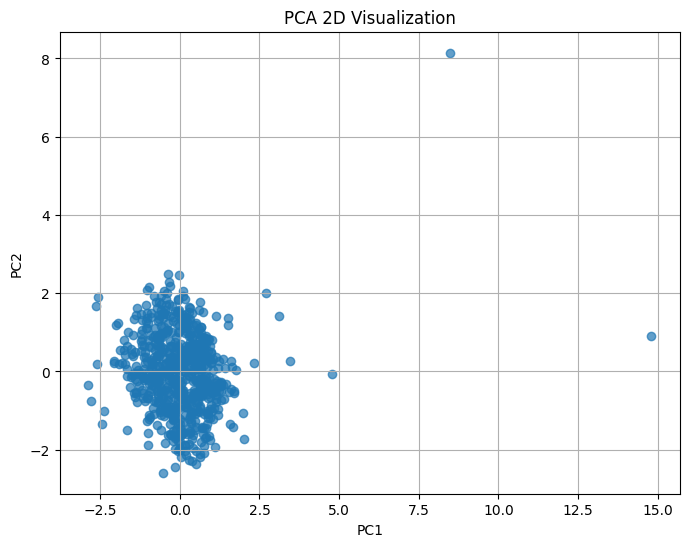

In [19]:
plt.figure(figsize=(8, 6))
plt.scatter(pca_data["PC1"], pca_data["PC2"], alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA 2D Visualization")
plt.grid(True)
plt.show()

## 18. Kiểm tra Explained Variance của PCA cuối cùng

In [20]:
print("Explained variance của các components được chọn:")

for i, variance in enumerate(
    pca.explained_variance_ratio_,
    start=1
):
    print(f"PC{i}: {variance * 100:.2f}%")

print(
    "\nTổng explained variance:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

Explained variance của các components được chọn:
PC1: 16.34%
PC2: 15.16%
PC3: 14.75%
PC4: 14.47%
PC5: 13.59%
PC6: 13.37%

Tổng explained variance: 87.69%


## 19. Lưu thông tin PCA

In [21]:
pca_info = pd.DataFrame({
    "Thông tin": [
        "Số biến ban đầu",
        "Số components được chọn",
        "Cumulative Explained Variance",
        "Phương pháp Scaling"
    ],
    "Giá trị": [
        len(pca_features),
        n_components,
        f"{cumulative_variance[n_components - 1] * 100:.2f}%",
        "StandardScaler"
    ]
})

display(pca_info)

pca_info.to_csv(
    "pca_info.csv",
    index=False,
    encoding="utf-8-sig"
)

,Thông tin,Giá trị
0,Số biến ban đầu,7
1,Số components được chọn,6
2,Cumulative Explained Variance,87.69%
3,Phương pháp Scaling,StandardScaler


In [22]:
pca_data = pd.DataFrame(
    X_pca,
    columns=pca_columns
)

pca_data.insert(0, "original_index", df.index)

display(pca_data.head())

pca_data.to_csv(
    "pca_data.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã cập nhật file pca_data.csv")

,original_index,PC1,PC2,PC3,PC4,PC5,PC6
0,0,-0.799529,-0.745176,0.250662,0.651425,1.027834,1.584173
1,1,-0.714665,1.615627,-0.347595,0.434029,-0.324126,-0.246513
2,2,-0.159861,1.552173,-0.800068,-0.070809,0.372266,0.993834
3,3,0.379828,0.703338,0.183436,0.071977,0.442691,-0.357089
4,4,-0.008098,-1.805640,0.345686,0.025658,-0.766348,-0.228735


Đã cập nhật file pca_data.csv
